# 03 — k-En Yakın Komşu (KNN) ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

KNN, tahmin için özellik uzayındaki en yakın **k** komşuya bakar: regresyonda bu
komşuların ortalamasını, sınıflandırmada çoğunluk oyunu kullanır. Ayrı bir "öğrenme"
aşaması yoktur; bütün iş tahmin anında yapılır, bu yüzden tembel (lazy) öğrenici olarak
anılır. Uzaklık hesabına dayandığı için özelliklerin ölçeklenmesi zorunludur. Bu
çalışmada bir noktanın "komşuları", topografyası, iklimi, bitki örtüsü ve yerleşime
uzaklığı ona en çok benzeyen noktalardır. Komşu sayısı doğrulama kümesiyle **k = 10**
olarak seçilmiştir.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
X_tr_s, X_te_s = o.olcekli(X_tr, X_te)
reg_model = KNeighborsRegressor(n_neighbors=10)   # k = 10 (doğrulama kümesiyle seçildi)
reg_model.fit(X_tr_s, yr_tr)
y_pred = reg_model.predict(X_te_s)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.2368
   MSE: 0.1190
  RMSE: 0.3450
    R2: 0.5237
   AUC: 0.9077


In [3]:
o.reg_grafikleri(yr_te, y_pred, "k-En Yakın Komşu (KNN)", "knn")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\knn_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = KNeighborsClassifier(n_neighbors=10)
clf.fit(X_tr_s, yc_tr)
yp = clf.predict(X_te_s)

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.8385
   BalancedAcc: 0.8392
      F1_macro: 0.8385
   F1_weighted: 0.8384

              precision    recall  f1-score   support

  Yangın Yok      0.869     0.804     0.835       653
      Yangın      0.811     0.874     0.842       629

    accuracy                          0.839      1282
   macro avg      0.840     0.839     0.838      1282
weighted avg      0.841     0.839     0.838      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.2368 |   0.4998 |    0.3931 | -0.1562 (iyi)
     MSE |   0.1190 |   0.2499 |    0.1978 | -0.0788 (iyi)
    RMSE |   0.3450 |   0.4999 |    0.4447 | -0.0997 (iyi)
      R2 |   0.5237 |  -0.0000 |    0.2086 | +0.3151 (iyi)
     AUC |   0.9077 |   0.5000 |    0.6982 | +0.2095 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.8385 |   0.5094 |    0.6934 | +0.1451
     BalancedAcc |  0.8392 |   0.5000 |    0.6982 | +0.1410
        F1_macro |  0.8385 |   0.3375 |    0.6748 | +0.1637
     F1_weighted |  0.8384 |   0.3438 |    0.6733 | +0.1651
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "k-En Yakın Komşu (KNN)", "knn")

k-En Yakın Komşu (KNN) — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   525    128
      Yangın |    79    550


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\knn_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### k Değerinin Etkisi

k, modelin karmaşıklığını belirleyen tek düğmedir. Küçük k → tahmin birkaç komşuya
bağlı kalır, gürültüye duyarlı olur (aşırı öğrenme). Büyük k → komşu havuzu genişler,
model ortalamaya doğru yassılaşır (eksik öğrenme). Aşağıdaki eğriler bu dengeyi test
kümesi üzerinde gösterir; seçim ise önceden, doğrulama kümesiyle yapılmıştır.

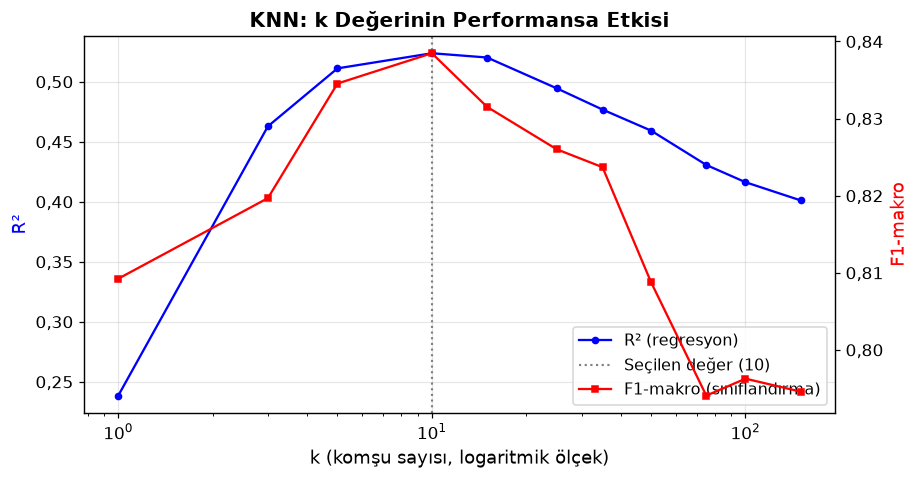

Tarama: [(1, 0.2384, 0.8092), (3, 0.4628, 0.8197), (5, 0.5111, 0.8345), (10, 0.5237, 0.8385), (15, 0.5201, 0.8315), (25, 0.4945, 0.826), (35, 0.4768, 0.8237), (50, 0.4592, 0.8088), (75, 0.4306, 0.7941), (100, 0.4162, 0.7963), (150, 0.4011, 0.7946)]
En yüksek R²: 0.5237 (10) · en yüksek F1-makro: 0.8385 (10)


In [7]:
degerler = [1, 3, 5, 10, 15, 25, 35, 50, 75, 100, 150]
r2_list, f1_list = [], []
for kk in degerler:
    r = KNeighborsRegressor(n_neighbors=kk).fit(X_tr_s, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te_s))["R2"])
    c = KNeighborsClassifier(n_neighbors=kk).fit(X_tr_s, yc_tr)
    f1_list.append(o.cls_metrikleri(yc_te, c.predict(X_te_s))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(10, color="gray", ls=":", lw=1.4, label="Seçilen değer (10)")
ax1.set_xlabel("k (komşu sayısı, logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("KNN: k Değerinin Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "knn_k_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [8]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    _olcek = o.StandardScaler().fit(Xa)
    Xa, Xb = _olcek.transform(Xa), _olcek.transform(Xb)
    r_tahmin = KNeighborsRegressor(n_neighbors=10).fit(Xa, yra).predict(Xb)
    c_tahmin = KNeighborsClassifier(n_neighbors=10).fit(Xa, ysa).predict(Xb)
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² +0.2346 · F1-makro 0.7230
  kat 2: eğitim  4170 · sınama   958 · R² +0.1436 · F1-makro 0.6252
  kat 3: eğitim  4114 · sınama  1014 · R² +0.4292 · F1-makro 0.8181


  kat 4: eğitim  4055 · sınama  1073 · R² +0.4189 · F1-makro 0.7974


  kat 5: eğitim  4150 · sınama   978 · R² +0.4979 · F1-makro 0.8374
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.3449 ± 0.1332
  F1-makro: 0.7602 ± 0.0779


In [9]:
o.sonuc_kaydet("knn", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\knn.json


{'algoritma': 'knn',
 'regresyon': {'MAE': 0.23681747269890796,
  'MSE': 0.11903276131045244,
  'RMSE': 0.3450112480926563,
  'R2': 0.5237020283052172,
  'AUC': 0.907674497306062},
 'siniflandirma': {'Accuracy': 0.8385335413416537,
  'BalancedAcc': 0.8391927194287342,
  'F1_macro': 0.8384721154495802,
  'F1_weighted': 0.8384131465931898},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [0.2346113811015612,
    0.1435961646038738,
    0.4292297276791448,
    0.4188662427022519,
    0.49794854417670675],
   'F1_macro': [0.7229568962126873,
    0.6251901191821085,
    0.8180981499391633,
    0.7973577598398642,
    0.8373850599053185],
   'R2_ort': 0.3448504120527077,
   'R2_std': 0.1331864604330558,
   'F1_ort': 0.7601975970158283,
   'F1_std': 0.07785261077778266},
  'duyarlilik': {'degerler': [1.0,
    3.0,
    5.0,
    10.0,
    15.0,
    25.0,
    35.0,
    50.0,
    75.0,
    100.0,
    150.0],
   'R2': [0.23842264027832893,
    0.46280358369359353,
    0.5110923048081861,
    0.